**Week 2: Assignment 3 Script**

In [39]:
import numpy as np
import matplotlib.pyplot as plt


In [40]:
# Site and sea-state parameters (table column 4, 5, 6)
g = 9.81        # gravitational acceleration [m/s^2]
h = 25.0        # water depth [m]
Hm0 = 7         # significant wave height [m]
m0 = Hm0**2/16  # zeroth spectral moment [m^2]

# JONSWAP parameters (starting assumptions) SLIDE 2 LECTURE 5
Tp = 10.0       # peak period [s]  -> s0 ≈ 0.045, steep young wind sea 
fp = 1 / Tp     # peak frequency [Hz]
gamma = 3.3     # peak enhancement factor (standard JONSWAP)

In [41]:
# Frequency axis: start just above 0 (f^-5 blows up at f = 0)
# and cut off the high-frequency tail at 5*fp
f_min = 0.01
f_max = 5 * fp
f = np.linspace(f_min, f_max, 5000)   # [Hz]

In [42]:
#SLIDE 12 LECTURE 5

def jonswap(f, Hs, Tp, gamma=3.3):
    """JONSWAP variance density spectrum E(f) [m^2/Hz], written with Hs and Tp."""
    fp = 1 / Tp

    # Pierson-Moskowitz base shape
    E_pm = (5/16) * Hs**2 * fp**4 * f**(-5) * np.exp(-1.25 * (fp / f)**4)

    # Peak width: 0.07 left of the peak, 0.09 right of it
    sigma = np.where(f <= fp, 0.07, 0.09)

    # Peak enhancement
    peak = gamma ** np.exp(-(f - fp)**2 / (2 * sigma**2 * fp**2))

    # Normalisation so that m0 = Hs^2/16 still holds
    A_gamma = 1 - 0.287 * np.log(gamma)

    return A_gamma * E_pm * peak



In [43]:
E = jonswap(f, Hm0, Tp, gamma)

m0_num = np.trapezoid(E, f)       # area under the spectrum 
Hm0_num = 4 * np.sqrt(m0_num)

print(f"m0 target   = {m0:.3f} m^2")
print(f"m0 computed = {m0_num:.3f} m^2")
print(f"Hm0 computed = {Hm0_num:.2f} m")

m0 target   = 3.062 m^2
m0 computed = 3.066 m^2
Hm0 computed = 7.00 m


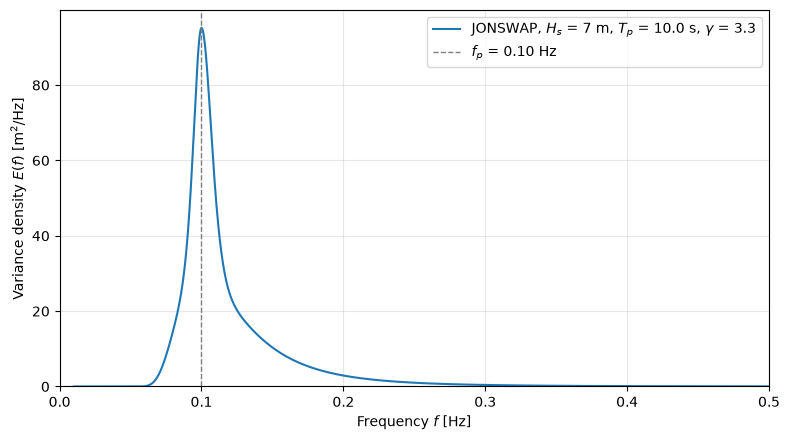

In [44]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(f, E, label=fr'JONSWAP, $H_s$ = {Hm0} m, $T_p$ = {Tp} s, $\gamma$ = {gamma}')
ax.axvline(fp, color='grey', ls='--', lw=1, label=fr'$f_p$ = {fp:.2f} Hz')
ax.set_xlabel('Frequency $f$ [Hz]')
ax.set_ylabel('Variance density $E(f)$ [m$^2$/Hz]')
ax.set_xlim(0, f_max)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig('jonswap_spectrum.pdf')   # vector figure for Overleaf
plt.show()

In [45]:
#SLIDE 9 LECTURE 5

def moment(n, f, E):
    """n-th spectral moment m_n = integral of f^n E(f) df"""
    return np.trapezoid(f**n * E, f)

m_min1 = moment(-1, f, E)
m0_s   = moment(0,  f, E)
m1     = moment(1,  f, E)
m2     = moment(2,  f, E)

Tm     = np.sqrt(m0_s / m2)   # = Tm02 ≈ Tz
Tm01   = m0_s / m1
Tm_10  = m_min1 / m0_s

print(f"Tm (=Tm02) = {Tm:.2f} s (Mean zero-crossing period)")
print(f"Tm01       = {Tm01:.2f} s (Mean period)")
print(f"Tm-1,0     = {Tm_10:.2f} s (Mean wave period)")
print(f"Tp         = {Tp:.2f} s (Peak period)")

Tm (=Tm02) = 7.93 s (Mean zero-crossing period)
Tm01       = 8.39 s (Mean period)
Tm-1,0     = 9.04 s (Mean wave period)
Tp         = 10.00 s (Peak period)


In [46]:
def wave_steepness(Hm0, T):
    """Wave steepness s0 = Hm0 / (g T^2)"""
    L = 1.56 * T**2
    return Hm0 / L

steepness_Tp = wave_steepness(Hm0, Tp)

print(f"Wave steepness s_op = {steepness_Tp:.3f} (for Tp = {Tp:.2f} s)")

Wave steepness s_op = 0.045 (for Tp = 10.00 s)


**Assingment 4**

In [47]:
# --- Question 4a: random-phase synthesis (linear) ---
D  = 3600.0          # record length [s]  (1 hour)
dt = 0.25            # time step [s]     -> Nyquist 2 Hz >> f_max
df = 1 / D           # frequency resolution [Hz]; record repeats after 1/df

f_syn = np.arange(df, 5*fp + df/2, df)    # component frequencies [Hz]
t     = np.arange(0, D, dt)               # time axis [s]

In [48]:
def wavenumber(f, h, g=9.81):
    """Deep water wavenumber (assumption)."""
    omega = 2 * np.pi * np.asarray(f)
    k = omega**2 / g                        # deep-water start value
    return k

E_syn = jonswap(f_syn, Hm0, Tp, gamma)      # your spectrum on the synthesis grid
a     = np.sqrt(2 * E_syn * df)             # component amplitudes (L5 app. 2/4)
omega = 2 * np.pi * f_syn
k     = wavenumber(f_syn, h)

rng   = np.random.default_rng(seed=42)      # fixed seed = reproducible realisation
alpha = rng.uniform(0, 2*np.pi, size=f_syn.size)   # random phases, uniform [0, 2pi)

In [54]:

rho = 1025
g = 9.81
Hu_surface = omega * np.cosh(k * h) / np.sinh(k * h)         # u-amplitude per m of eta, z = 0
Hp_bed = rho * g/np.cosh(k*h)
Hu_bed = omega / np.sinh(k * h)                              # u-amplitude per m of eta, z = -h
eta = np.zeros_like(t)
u_surface   = np.zeros_like(t)
u_bed   = np.zeros_like(t)
p_bed = np.zeros_like(t)
for i in range(f_syn.size):
    phase = -omega[i] * t + alpha[i]       # x = 0: the k*x term is absorbed in alpha
    eta  += a[i] * np.cos(phase)
    u_surface   += a[i] * Hu_surface[i] * np.cos(phase)
    u_bed   += a[i] * Hu_bed[i] * np.cos(phase)  # in phase with eta (L3 slide 16)
    p_bed   += a[i] * Hp_bed[i] * np.cos(phase)  # in phase with eta (L3 slide 16)
    

Hs from record  = 7.00 m   (target 7 m)
mean eta        = -1.4e-15 m (should be ~0)
Tz from record  = 7.83 s   (compare Tm = Tm02)


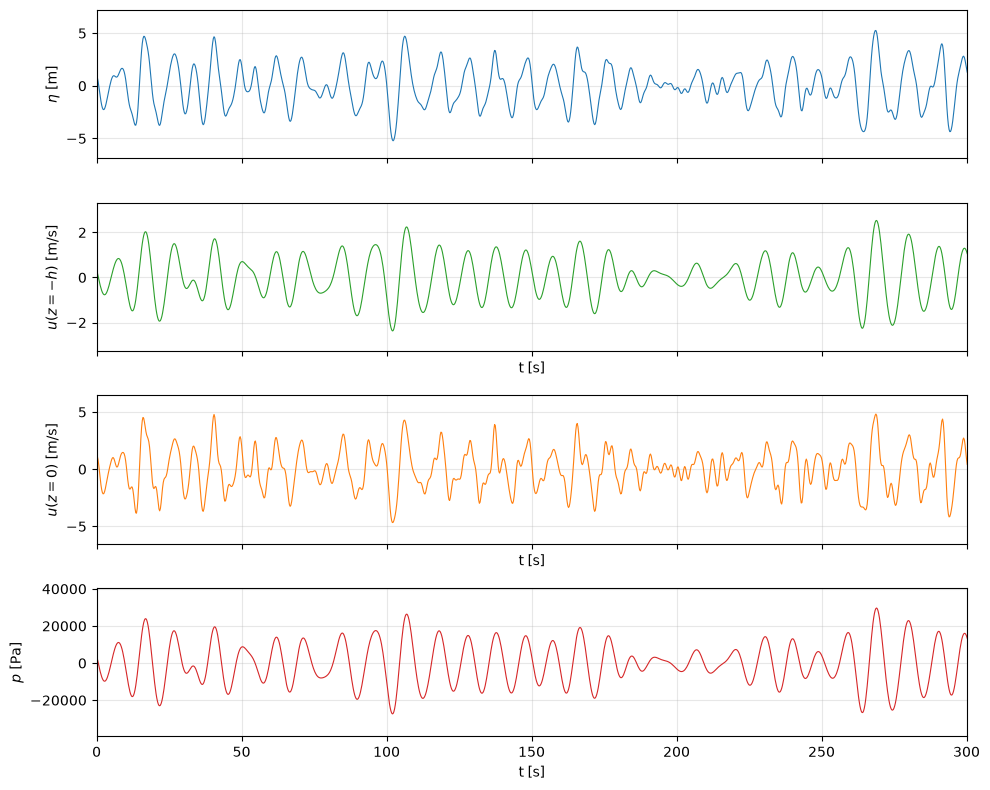

In [55]:
print(f"Hs from record  = {4*np.std(eta):.2f} m   (target {Hm0} m)")
print(f"mean eta        = {np.mean(eta):.1e} m (should be ~0)")
#print(f"u_rms record    = {np.std(u):.3f} m/s")
#print(f"u_rms spectrum  = {np.sqrt(np.sum((a*Hu)**2)/2):.3f} m/s 

# zero-crossing period (L5 slide 6) -> compare with your Tm from question 3
up = np.where((eta[:-1] < 0) & (eta[1:] >= 0))[0]
print(f"Tz from record  = {D/len(up):.2f} s   (compare Tm = Tm02)")

fig, axs = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
axs[0].plot(t, eta, lw=0.8); axs[0].set_ylabel(r'$\eta$ [m]')
axs[1].plot(t, u_bed, lw=0.8, color='C2'); axs[1].set_ylabel(r'$u(z=-h)$ [m/s]')
axs[1].set_xlabel('t [s]'); axs[1].set_xlim(0, 300)
axs[2].plot(t, u_surface, lw=0.8, color='C1'); axs[2].set_ylabel(r'$u(z=0)$ [m/s]')
axs[2].set_xlabel('t [s]'); axs[2].set_xlim(0, 300)   # zoom in on 5 minutes
axs[3].plot(t, p_bed, lw=0.8, color='C3'); axs[3].set_ylabel(r'$p$ [Pa]')
axs[3].set_xlabel('t [s]'); axs[3].set_xlim(0, 300)   # zoom in on 5 minutes
for ax in axs: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()